# Panduan Latihan UTS Data Analysis Lab

**Fokus:** Dataset understanding, data formatting, visualisasi, deteksi outlier dengan Z-score, serta data preprocessing.

Notebook ini disusun dari tiga sumber dengan urutan prioritas:
1. **Rubrik dosen UTS Lab** sebagai acuan utama.
2. **Jawaban UTS Lab tahun 2025** sebagai referensi pola pengerjaan, termasuk contoh `Passengers.csv`, `Stations.xlsx`, dan `Routes.xlsx`.
3. **Materi LEC Datnal** sebagai tambahan pola preprocessing, Pandas/NumPy, dan EDA.

> **Penting:** Dataset latihan di notebook ini adalah data ilustrasi agar semua sel bisa langsung dijalankan. Data dan angka output bukan salinan lengkap dataset ujian tahun lalu dan bukan prediksi pasti soal besok. Saat UTS, ikuti nama file, nama kolom, ambang batas, dan instruksi yang benar-benar diberikan dosen.

## Peta materi

| Bagian | Materi yang dilatih |
|---|---|
| Q1 | Dimensi, tipe data, missing values, duplikat, konversi numerik, statistik deskriptif, 5 baris awal/akhir, dan merge dataset |
| Q2 | Membuat variabel hasil perhitungan, membuat kategori, boxplot, histogram, dan bar chart |
| Q3 | Z-score, daftar outlier, jumlah dan persentase outlier |
| Q4 | Membuat kolom kategori berdasarkan batas nilai dan validasi hasil |
| Tambahan | Imputasi, IQR, `groupby`, `value_counts`, `np.where`, list/dictionary/set, dan tanggal |

## Cara mengganti dataset ketika ujian

Jika dosen memberi tiga file seperti referensi tahun 2025, contoh pembacaannya:

```python
import pandas as pd

dfRoutes = pd.read_excel('Routes.xlsx')
dfStations = pd.read_excel('Stations.xlsx')
dfPassengers = pd.read_csv('Passengers.csv')
```

Jika nama file berbeda, ganti nama file di dalam tanda kutip. Kalau nama kolom berbeda, ganti nama kolom pada kode berikutnya. Untuk file Excel dengan beberapa sheet, cek `pd.ExcelFile('nama_file.xlsx').sheet_names` lalu tentukan `sheet_name` jika diperlukan.

**Urutan aman saat ujian:** baca file → cek struktur/kualitas → gabungkan bila diminta → buat variabel turunan → visualisasi/EDA → preprocessing → tampilkan hasil yang diminta.

## 0. Import library

Paket yang umum digunakan pada contoh ini: Pandas, NumPy, Matplotlib, Seaborn, dan SciPy. Jika environment ujian sudah menyediakan library, tidak perlu menginstal ulang.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 140)

print('Library berhasil di-import')

Library berhasil di-import


## Dataset latihan mandiri

Contoh mengikuti pola dataset transportasi di referensi UTS 2025: data penumpang, metadata stasiun, dan metadata rute. Data ini dibuat untuk latihan mandiri; gunakan blok pembacaan file pada bagian sebelumnya ketika dosen memberikan file asli.

In [2]:
# Dataset 1: catatan penumpang harian
passenger_values = [
    318, 872, 403, 730, 460, 4239, 308, 615, 271, 458,
    201, 201, 201, 201, 201, 201, 201,
    954, 954, 954, 954, 954, 954, 954,
    3780, 4866, 250, 851, 794, 445
]
station_ids = [
    5, 2, 5, 2, 4, 3, 2, 1, 2, 3,
    4, 1, 5, 3, 2, 4, 3, 1, 5, 2,
    4, 3, 5, 3, 4, 1, 1, 1, 2, 2
]

dfPassengers = pd.DataFrame({
    'Date': pd.date_range('2025-01-01', periods=30, freq='D'),
    'Station_ID': station_ids,
    'Passengers': passenger_values
})

# Dataset 2: detail nama stasiun dan zona
dfStations = pd.DataFrame({
    'Station_ID': [1, 2, 3, 4, 5],
    'Station_Name': ['Central', 'North', 'East', 'South', 'West'],
    'Zone': ['Urban', 'Suburban', 'Urban', 'Suburban', 'Urban']
})

# Dataset 3: detail rute, jenis transportasi, dan tarif
dfRoutes = pd.DataFrame({
    'Station_ID': [1, 2, 3, 4, 5],
    'Route_ID': [101, 102, 103, 104, 105],
    'Transport_Type': ['Bus', 'Train', 'MRT', 'Bus', 'Train'],
    'Fare_USD': [0.50, 1.00, 0.75, 0.60, 1.20]
})

print('Passengers:', dfPassengers.shape)
print('Stations  :', dfStations.shape)
print('Routes    :', dfRoutes.shape)
display(dfPassengers.head())
display(dfStations)
display(dfRoutes)

Passengers: (30, 3)
Stations  : (5, 3)
Routes    : (5, 4)


,Date,Station_ID,Passengers
0,2025-01-01,5,318
1,2025-01-02,2,872
2,2025-01-03,5,403
3,2025-01-04,2,730
4,2025-01-05,4,460


,Station_ID,Station_Name,Zone
0,1,Central,Urban
1,2,North,Suburban
2,3,East,Urban
3,4,South,Suburban
4,5,West,Urban


,Station_ID,Route_ID,Transport_Type,Fare_USD
0,1,101,Bus,0.50
1,2,102,Train,1.00
2,3,103,MRT,0.75
3,4,104,Bus,0.60
4,5,105,Train,1.20


# Q1 — Dataset Understanding

Bagian Q1 pada rubrik menekankan pemeriksaan dimensi, tipe data, missing values dan duplikat, konversi tipe numerik, statistik dasar, serta tampilan lima baris pertama dan terakhir.

## 1A. Cek dimensi setiap dataset

`.shape` menghasilkan `(jumlah_baris, jumlah_kolom)`. Jangan tertukar membaca urutannya.

In [3]:
print("Dimension Routes   =", dfRoutes.shape)
print("Dimension Stations =", dfStations.shape)
print("Dimension Passengers =", dfPassengers.shape)

Dimension Routes   = (5, 4)
Dimension Stations = (5, 3)
Dimension Passengers = (30, 3)


## 1B. Cek tipe data, missing values, dan duplikat

Gunakan kode ini untuk setiap DataFrame. `isnull().sum()` menghitung nilai kosong per kolom, sementara `duplicated().sum()` menghitung baris duplikat penuh.

In [4]:
for nama, df in {
    'Routes': dfRoutes,
    'Stations': dfStations,
    'Passengers': dfPassengers
}.items():
    print(f'\n===== {nama} =====')
    print('Tipe data:')
    print(df.dtypes)
    print('Missing values per kolom:')
    print(df.isnull().sum())
    print('Jumlah baris duplikat:', df.duplicated().sum())


===== Routes =====
Tipe data:
Station_ID          int64
Route_ID            int64
Transport_Type     object
Fare_USD          float64
dtype: object
Missing values per kolom:
Station_ID        0
Route_ID          0
Transport_Type    0
Fare_USD          0
dtype: int64
Jumlah baris duplikat: 0

===== Stations =====
Tipe data:
Station_ID       int64
Station_Name    object
Zone            object
dtype: object
Missing values per kolom:
Station_ID      0
Station_Name    0
Zone            0
dtype: int64
Jumlah baris duplikat: 0

===== Passengers =====
Tipe data:
Date          datetime64[ns]
Station_ID             int64
Passengers             int64
dtype: object
Missing values per kolom:
Date          0
Station_ID    0
Passengers    0
dtype: int64
Jumlah baris duplikat: 0


## 1C. Konversi kolom ke numerik bila dibutuhkan

Kalau kolom angka terbaca sebagai teks (misalnya karena tanda koma atau karakter lain), konversikan terlebih dahulu. `errors='coerce'` mengubah nilai yang gagal dikonversi menjadi `NaN`, jadi periksa kembali hasilnya setelah konversi.

In [5]:
# Contoh aman jika Fare_USD berasal dari file asli dan belum bertipe angka
dfRoutes['Fare_USD'] = pd.to_numeric(dfRoutes['Fare_USD'], errors='coerce')
print(dfRoutes.dtypes)
print('Missing setelah konversi Fare_USD:', dfRoutes['Fare_USD'].isna().sum())

Station_ID          int64
Route_ID            int64
Transport_Type     object
Fare_USD          float64
dtype: object
Missing setelah konversi Fare_USD: 0


## 1D. Gabungkan dataset menggunakan `Station_ID`

Di referensi UTS 2025, dataset penumpang menjadi tabel utama sehingga contoh menggunakan `how='left'`: semua baris penumpang dipertahankan, lalu informasi stasiun dan rute ditambahkan berdasarkan `Station_ID`.

In [6]:
mergedData = (
    dfPassengers
    .merge(dfStations, on='Station_ID', how='left')
    .merge(dfRoutes, on='Station_ID', how='left')
)

print('Dimension setelah merge:', mergedData.shape)
display(mergedData.head())

Dimension setelah merge: (30, 8)


,Date,Station_ID,Passengers,Station_Name,Zone,Route_ID,Transport_Type,Fare_USD
0,2025-01-01,5,318,West,Urban,105,Train,1.2
1,2025-01-02,2,872,North,Suburban,102,Train,1.0
2,2025-01-03,5,403,West,Urban,105,Train,1.2
3,2025-01-04,2,730,North,Suburban,102,Train,1.0
4,2025-01-05,4,460,South,Suburban,104,Bus,0.6


## 1E. Buat konversi mata uang dan tampilkan statistik dasar

Rumus pada referensi tahun lalu: `Fare_IDR = Fare_USD * 16000`. Saat ujian, gunakan kurs yang ditentukan oleh soal, bukan kurs yang diingat sendiri.

In [7]:
KURS_USD_IDR = 16000
mergedData['Fare_IDR'] = mergedData['Fare_USD'] * KURS_USD_IDR

print('Statistik deskriptif:')
display(mergedData.describe())

print('Tipe data setiap kolom:')
print(mergedData.dtypes)

print('5 baris pertama:')
display(mergedData.head(5))

print('5 baris terakhir:')
display(mergedData.tail(5))

Statistik deskriptif:


,Date,Station_ID,Passengers,Route_ID,Fare_USD,Fare_IDR
count,30,30.000000,30.000000,30.000000,30.000000,30.000000
mean,2025-01-15 12:00:00,2.833333,924.833333,102.833333,0.816667,13066.666667
min,2025-01-01 00:00:00,1.000000,201.000000,101.000000,0.500000,8000.000000
25%,2025-01-08 06:00:00,2.000000,255.250000,102.000000,0.600000,9600.000000
50%,2025-01-15 12:00:00,3.000000,537.500000,103.000000,0.750000,12000.000000
75%,2025-01-22 18:00:00,4.000000,954.000000,104.000000,1.000000,16000.000000
max,2025-01-30 00:00:00,5.000000,4866.000000,105.000000,1.200000,19200.000000
std,NaN,1.391683,1190.037208,1.391683,0.253708,4059.330107


Tipe data setiap kolom:
Date              datetime64[ns]
Station_ID                 int64
Passengers                 int64
Station_Name              object
Zone                      object
Route_ID                   int64
Transport_Type            object
Fare_USD                 float64
Fare_IDR                 float64
dtype: object
5 baris pertama:


,Date,Station_ID,Passengers,Station_Name,Zone,Route_ID,Transport_Type,Fare_USD,Fare_IDR
0,2025-01-01,5,318,West,Urban,105,Train,1.2,19200.0
1,2025-01-02,2,872,North,Suburban,102,Train,1.0,16000.0
2,2025-01-03,5,403,West,Urban,105,Train,1.2,19200.0
3,2025-01-04,2,730,North,Suburban,102,Train,1.0,16000.0
4,2025-01-05,4,460,South,Suburban,104,Bus,0.6,9600.0


5 baris terakhir:


,Date,Station_ID,Passengers,Station_Name,Zone,Route_ID,Transport_Type,Fare_USD,Fare_IDR
25,2025-01-26,1,4866,Central,Urban,101,Bus,0.5,8000.0
26,2025-01-27,1,250,Central,Urban,101,Bus,0.5,8000.0
27,2025-01-28,1,851,Central,Urban,101,Bus,0.5,8000.0
28,2025-01-29,2,794,North,Suburban,102,Train,1.0,16000.0
29,2025-01-30,2,445,North,Suburban,102,Train,1.0,16000.0


### Arti hasil yang perlu dipahami

- `count`: jumlah nilai yang tidak kosong.
- `mean`: rata-rata.
- `std`: standar deviasi, ukuran penyebaran nilai.
- `min` dan `max`: nilai minimum dan maksimum.
- `25%`, `50%`, `75%`: kuartil pertama, median, dan kuartil ketiga.
- Jika jumlah baris setelah `merge` bertambah tidak wajar, periksa apakah key di tabel metadata memiliki nilai duplikat. Satu `Station_ID` yang cocok ke lebih dari satu baris dapat menggandakan baris hasil merge.

# Q2 — Data Formatting & Visualization

Rubrik meminta pembuatan variabel baru melalui perhitungan dan visualisasi. Contoh tahun lalu menggunakan kategori tarif, boxplot, histogram 50 bins, dan bar chart rata-rata penumpang per jenis transportasi. Jika soal terbaru meminta variabel/grafik berbeda, pertahankan pola sintaks lalu ganti variabel dan kriteria sesuai instruksi.

## 2A. Membuat variabel baru dari dua variabel

**Pola umum** (ganti nama variabel dan operasi aritmetika mengikuti soal):

```python
df['New_Column'] = df['Variable_1'] * df['Variable_2']
```

Contoh bermakna untuk data latihan: estimasi pendapatan = jumlah penumpang × tarif per penumpang dalam Rupiah. Pastikan perhitungan ini masuk akal menurut definisi kolom di soal.

In [8]:
mergedData['Estimated_Revenue_IDR'] = mergedData['Passengers'] * mergedData['Fare_IDR']
display(mergedData[['Passengers', 'Fare_IDR', 'Estimated_Revenue_IDR']].head(10))

,Passengers,Fare_IDR,Estimated_Revenue_IDR
0,318,19200.0,6105600.0
1,872,16000.0,13952000.0
2,403,19200.0,7737600.0
3,730,16000.0,11680000.0
4,460,9600.0,4416000.0
5,4239,12000.0,50868000.0
6,308,16000.0,4928000.0
7,615,8000.0,4920000.0
8,271,16000.0,4336000.0
9,458,12000.0,5496000.0


## 2B. Membuat kategori tarif (`Fare_Category`)

Contoh dari referensi tahun lalu:
- kurang dari Rp10.000 → `Low`
- Rp10.000 sampai Rp20.000 (termasuk kedua batas) → `Medium`
- lebih dari Rp20.000 → `High`

`np.select` dipakai di sini agar batas 10.000 dan 20.000 terbaca sesuai kalimat soal.

In [9]:
conditions_fare = [
    mergedData['Fare_IDR'] < 10000,
    mergedData['Fare_IDR'].between(10000, 20000, inclusive='both')
]
choices_fare = ['Low', 'Medium']
mergedData['Fare_Category'] = np.select(conditions_fare, choices_fare, default='High')

display(mergedData[['Fare_IDR', 'Fare_Category']].head(10))
print(mergedData['Fare_Category'].value_counts(dropna=False))

,Fare_IDR,Fare_Category
0,19200.0,Medium
1,16000.0,Medium
2,19200.0,Medium
3,16000.0,Medium
4,9600.0,Low
5,12000.0,Medium
6,16000.0,Medium
7,8000.0,Low
8,16000.0,Medium
9,12000.0,Medium


Fare_Category
Medium    19
Low       11
Name: count, dtype: int64


## 2C. Visualisasi 1 — Boxplot jumlah penumpang berdasarkan zona

Boxplot membantu membandingkan median, sebaran, dan kemungkinan nilai ekstrem pada setiap kelompok kategori.

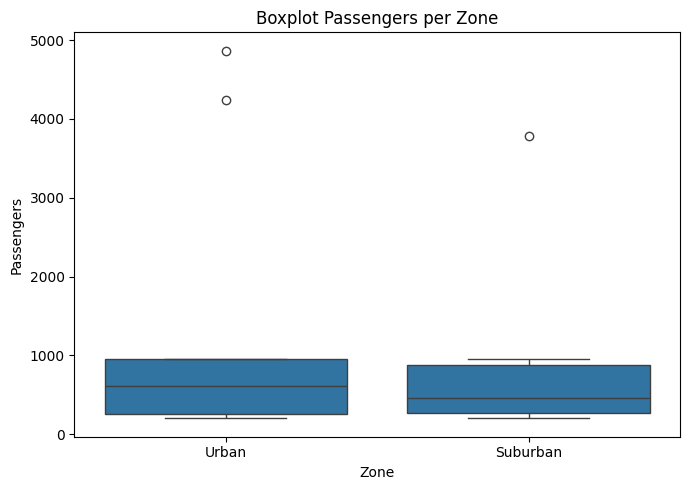

In [10]:
plt.figure(figsize=(7, 5))
sns.boxplot(data=mergedData, x='Zone', y='Passengers')
plt.title('Boxplot Passengers per Zone')
plt.xlabel('Zone')
plt.ylabel('Passengers')
plt.tight_layout()
plt.show()

## 2D. Visualisasi 2 — Histogram tarif dengan 50 bins

Histogram menampilkan distribusi satu variabel numerik. `bins=50` harus dipakai jika itu diminta secara spesifik dalam soal.

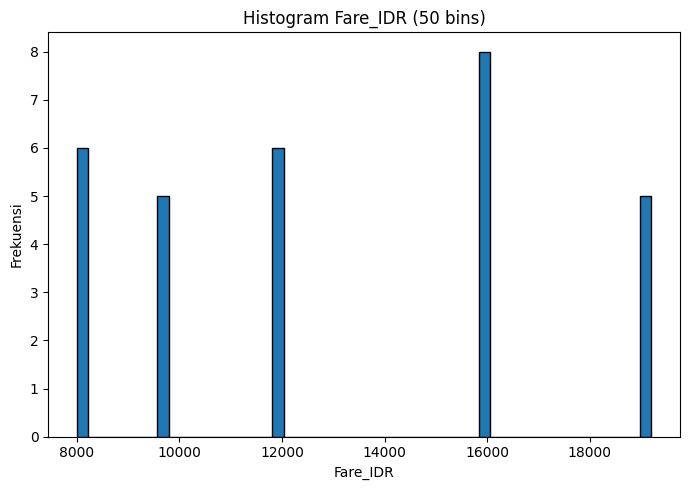

In [11]:
plt.figure(figsize=(7, 5))
plt.hist(mergedData['Fare_IDR'].dropna(), bins=50, edgecolor='black')
plt.title('Histogram Fare_IDR (50 bins)')
plt.xlabel('Fare_IDR')
plt.ylabel('Frekuensi')
plt.tight_layout()
plt.show()

## 2E. Visualisasi 3 — Bar chart rata-rata penumpang per jenis transportasi

`groupby` menghitung rata-rata untuk masing-masing jenis transportasi. Bar chart cocok untuk membandingkan besaran antar kategori.

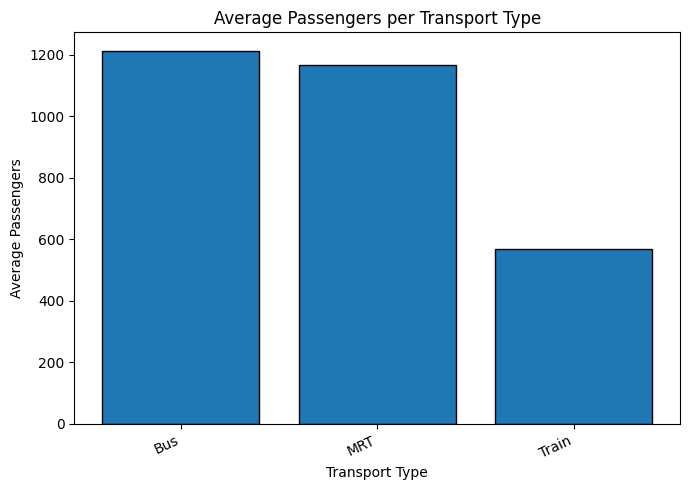

Transport_Type
Bus      1212.090909
MRT      1167.833333
Train     569.615385
Name: Passengers, dtype: float64


In [12]:
avgPassengers = (
    mergedData.groupby('Transport_Type', dropna=False)['Passengers']
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(7, 5))
plt.bar(avgPassengers.index.astype(str), avgPassengers.values, edgecolor='black')
plt.title('Average Passengers per Transport Type')
plt.xlabel('Transport Type')
plt.ylabel('Average Passengers')
plt.xticks(rotation=25, ha='right')
plt.tight_layout()
plt.show()

print(avgPassengers)

### Cara menulis interpretasi grafik

Tulis **apa yang terlihat → perbandingan/pola → maknanya secara hati-hati**. Contoh: "Boxplot menunjukkan median jumlah penumpang di zona A lebih tinggi daripada zona B. Zona A juga memiliki sebaran lebih lebar dan satu nilai yang jauh dari kelompok utama. Ini menunjukkan variasi jumlah penumpang di zona A lebih besar; penyebabnya tidak dapat dipastikan hanya dari grafik."

# Q3 — Exploratory Data Analysis: Z-score dan Outlier

Rubrik meminta Z-score untuk kolom yang ditentukan, lalu menghitung jumlah dan persentase outlier dari total baris.

Rumus:

\[
z = \frac{x - \mu}{\sigma}
\]

Dalam contoh ini, aturan latihan adalah nilai dengan `|Z-score| > 3` dianggap outlier. Jika soal menyebut ambang lain, gunakan ambang yang disebutkan soal.

In [13]:
# Hitung Z-score pada kolom Passengers
z_scores = pd.Series(
    stats.zscore(mergedData['Passengers'], nan_policy='omit'),
    index=mergedData.index,
    name='Z_score'
)

# Ambang contoh: nilai absolut Z-score lebih besar dari 3
outlier_mask = z_scores.abs() > 3
outliers = mergedData.loc[outlier_mask].copy()
mergedData_no_outlier = mergedData.loc[~outlier_mask].copy()

# Jumlah dan persentase outlier
rows_total = len(mergedData)
outlier_count = int(outlier_mask.sum())
outlier_percentage = (outlier_count / rows_total * 100) if rows_total else 0

print('Jumlah baris sebelum deteksi:', rows_total)
print('Jumlah outlier:', outlier_count)
print('Persentase outlier: {:.2f}%'.format(outlier_percentage))
print('Shape sebelum filter:', mergedData.shape)
print('Shape setelah filter:', mergedData_no_outlier.shape)

display(outliers[['Date', 'Station_ID', 'Station_Name', 'Passengers']])

Jumlah baris sebelum deteksi: 30
Jumlah outlier: 1
Persentase outlier: 3.33%
Shape sebelum filter: (30, 11)
Shape setelah filter: (29, 11)


,Date,Station_ID,Station_Name,Passengers
25,2025-01-26,1,Central,4866


### Jangan salah menafsirkan hasil outlier

- Kode di atas **mendeteksi** outlier dan membuat DataFrame hasil filter terpisah. Data asli `mergedData` tidak dihapus.
- Jangan otomatis menghapus outlier kecuali soal meminta penghapusan. Nilai ekstrem bisa merupakan kesalahan data, tetapi bisa juga merupakan kejadian yang nyata dan penting.
- Rumus persentase: `jumlah_outlier / total_baris * 100`.
- Pastikan nama variabel konsisten. Kesalahan seperti mendefinisikan `outlierCount` tetapi menghitung `outlier_count` akan menghasilkan `NameError` karena Python membedakan huruf besar dan kecil.

# Q4 — Data Preprocessing & Preparation: Membuat Kategori

Contoh mengikuti pola referensi tahun lalu: buat kolom `Passenger_Level` berdasarkan jumlah penumpang.
- kurang dari 300 → `Low`
- 300 sampai 700 (inklusif) → `Medium`
- lebih dari 700 → `High`

`np.select` memperjelas batas inklusif agar tepat sesuai kalimat soal.

In [14]:
conditions_passenger = [
    mergedData['Passengers'] < 300,
    mergedData['Passengers'].between(300, 700, inclusive='both')
]
choices_passenger = ['Low', 'Medium']
mergedData['Passenger_Level'] = np.select(
    conditions_passenger,
    choices_passenger,
    default='High'
)

display(mergedData[['Passengers', 'Passenger_Level']].head(15))
print(mergedData['Passenger_Level'].value_counts(dropna=False))

,Passengers,Passenger_Level
0,318,Medium
1,872,High
2,403,Medium
3,730,High
4,460,Medium
5,4239,High
6,308,Medium
7,615,Medium
8,271,Low
9,458,Medium


Passenger_Level
High      14
Low        9
Medium     7
Name: count, dtype: int64


## Alternatif menggunakan `pd.cut`

Pola ini umum dipakai untuk binning. Jika data `Passengers` berupa bilangan bulat, batas `[300, 701)` akan memasukkan nilai 300 hingga 700 ke kelompok `Medium`.

In [15]:
mergedData['Passenger_Level_cut'] = pd.cut(
    mergedData['Passengers'],
    bins=[-np.inf, 300, 701, np.inf],
    labels=['Low', 'Medium', 'High'],
    right=False
)

display(mergedData[['Passengers', 'Passenger_Level', 'Passenger_Level_cut']].head(15))

,Passengers,Passenger_Level,Passenger_Level_cut
0,318,Medium,Medium
1,872,High,High
2,403,Medium,Medium
3,730,High,High
4,460,Medium,Medium
5,4239,High,High
6,308,Medium,Medium
7,615,Medium,Medium
8,271,Low,Low
9,458,Medium,Medium


# Tambahan dari materi LEC — Preprocessing dan operasi umum

Bagian ini adalah bekal tambahan. Gunakan hanya jika relevan dengan instruksi soal Lab.

## A. Contoh memeriksa dan membersihkan data kualitas rendah

Contoh terpisah berikut sengaja memiliki duplikat dan nilai kosong untuk menunjukkan cara menangani masalah kualitas data. **Jangan langsung menyalin metode cleaning ini ke semua kolom**; pilih teknik sesuai tipe data dan instruksi soal.

In [16]:
quality_demo = pd.DataFrame({
    'Age': [25, 37, np.nan, 33, 33, 45],
    'City': ['Jakarta', 'Bandung', 'Medan', 'Bali', 'Bali', np.nan],
    'Monthly_Income': [8_500_000, 12_000_000, 15_000_000, 10_500_000, 10_500_000, 95_000_000]
})

print('Sebelum cleaning:')
print('Missing values per kolom:\n', quality_demo.isna().sum())
print('Jumlah duplikat:', quality_demo.duplicated().sum())
display(quality_demo)

quality_clean = quality_demo.drop_duplicates().copy()
quality_clean['Age'] = quality_clean['Age'].fillna(quality_clean['Age'].median())
quality_clean['Monthly_Income'] = quality_clean['Monthly_Income'].fillna(quality_clean['Monthly_Income'].median())
quality_clean['City'] = quality_clean['City'].fillna(quality_clean['City'].mode()[0])
quality_clean['Age'] = quality_clean['Age'].astype(int)

print('Sesudah drop duplicate dan imputasi:')
print('Missing values tersisa:', int(quality_clean.isna().sum().sum()))
print('Duplikat tersisa:', int(quality_clean.duplicated().sum()))
display(quality_clean)

Sebelum cleaning:
Missing values per kolom:
 Age               1
City              1
Monthly_Income    0
dtype: int64
Jumlah duplikat: 1


,Age,City,Monthly_Income
0,25.0,Jakarta,8500000
1,37.0,Bandung,12000000
2,NaN,Medan,15000000
3,33.0,Bali,10500000
4,33.0,Bali,10500000
5,45.0,NaN,95000000


Sesudah drop duplicate dan imputasi:
Missing values tersisa: 0
Duplikat tersisa: 0


,Age,City,Monthly_Income
0,25,Jakarta,8500000
1,37,Bandung,12000000
2,35,Medan,15000000
3,33,Bali,10500000
5,45,Bali,95000000


### B. Deteksi outlier dengan IQR (alternatif Z-score)

IQR adalah `Q3 - Q1`; batas bawah = `Q1 - 1.5 × IQR`; batas atas = `Q3 + 1.5 × IQR`. Pakai metode yang diminta dosen. Di rubrik Lab yang terlihat, metode Z-score disebut secara khusus untuk soal outlier; IQR disertakan sebagai referensi tambahan LEC.

In [17]:
q1 = quality_clean['Monthly_Income'].quantile(0.25)
q3 = quality_clean['Monthly_Income'].quantile(0.75)
iqr = q3 - q1
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

iqr_outliers = quality_clean[
    (quality_clean['Monthly_Income'] < lower_bound) |
    (quality_clean['Monthly_Income'] > upper_bound)
]

print(f'Q1={q1:,.0f}; Q3={q3:,.0f}; IQR={iqr:,.0f}')
print(f'Batas bawah={lower_bound:,.0f}; batas atas={upper_bound:,.0f}')
display(iqr_outliers[['City', 'Monthly_Income']])

# Contoh winsorizing: nilai di luar batas dipotong pada batas terdekat, bukan dihapus
quality_clean['Income_Clipped'] = quality_clean['Monthly_Income'].clip(
    lower=lower_bound,
    upper=upper_bound
)
display(quality_clean[['Monthly_Income', 'Income_Clipped']])

Q1=10,500,000; Q3=15,000,000; IQR=4,500,000
Batas bawah=3,750,000; batas atas=21,750,000


,City,Monthly_Income
5,Bali,95000000


,Monthly_Income,Income_Clipped
0,8500000,8500000
1,12000000,12000000
2,15000000,15000000
3,10500000,10500000
5,95000000,21750000


## C. Operasi Pandas / NumPy yang sering berguna

In [18]:
# 1. Ringkasan per kategori
sales_summary = mergedData.groupby('Transport_Type')['Estimated_Revenue_IDR'].agg(['count', 'sum', 'mean'])
display(sales_summary)

# 2. Frekuensi kategori
print(mergedData['Transport_Type'].value_counts(dropna=False))

# 3. Membuat label dengan kondisi
mergedData['Revenue_Level'] = np.where(
    mergedData['Estimated_Revenue_IDR'] >= 10_000_000,
    'Large',
    'Small'
)
print(mergedData['Revenue_Level'].value_counts())

# 4. Persentil ke-75
p75 = np.percentile(mergedData['Estimated_Revenue_IDR'].dropna(), 75)
print('Persentil ke-75:', round(p75, 2))

,count,sum,mean
Transport_Type,,,
Bus,11,115617600.0,1.051069e+07
MRT,6,84084000.0,1.401400e+07
Train,13,127536000.0,9.810462e+06


Transport_Type
Train    13
Bus      11
MRT       6
Name: count, dtype: int64
Revenue_Level
Small    19
Large    11
Name: count, dtype: int64
Persentil ke-75: 12448000.0


## D. List, dictionary, set

- **List:** kumpulan nilai berurutan, bisa diubah, dan boleh memiliki nilai berulang.
- **Dictionary:** pasangan `key: value`, berguna untuk mapping atau lookup.
- **Set:** menyimpan elemen unik dan mendukung irisan/selisih himpunan.

In [19]:
# List: daftar jenis transportasi
transport_list = mergedData['Transport_Type'].dropna().unique().tolist()
print('List:', transport_list)

# Dictionary: jenis transportasi -> rata-rata penumpang
dict_avg = mergedData.groupby('Transport_Type')['Passengers'].mean().round(1).to_dict()
print('Dictionary:', dict_avg)

# Set: membandingkan ID stasiun di dua dataset
passenger_station_ids = set(dfPassengers['Station_ID'])
metadata_station_ids = set(dfStations['Station_ID'])
print('Station_ID cocok:', passenger_station_ids & metadata_station_ids)
print('ID penumpang tanpa metadata:', passenger_station_ids - metadata_station_ids)

List: ['Train', 'Bus', 'MRT']
Dictionary: {'Bus': 1212.1, 'MRT': 1167.8, 'Train': 569.6}
Station_ID cocok: {1, 2, 3, 4, 5}
ID penumpang tanpa metadata: set()


## E. Konversi kolom tanggal

Jika tanggal berupa string, konversikan menjadi `datetime` agar bisa digunakan untuk pengurutan, filtering periode, atau menghitung jarak hari.

In [20]:
# Contoh mandiri dengan string tanggal
orders_demo = pd.DataFrame({'Order_Date': ['2026-08-03', '2026-08-21', '2026-09-14']})
orders_demo['Order_Date'] = pd.to_datetime(orders_demo['Order_Date'], errors='coerce')
print(orders_demo.dtypes)
display(orders_demo)

Order_Date    datetime64[ns]
dtype: object


,Order_Date
0,2026-08-03
1,2026-08-21
2,2026-09-14


# Checklist sebelum mengumpulkan jawaban

- [ ] Semua file dibaca dengan fungsi yang benar (`read_csv` untuk CSV, `read_excel` untuk Excel).
- [ ] Dimensi, tipe data, missing values, duplikat, statistik deskriptif, serta `head()` dan `tail()` ditampilkan sesuai permintaan.
- [ ] Proses `merge` menggunakan key yang benar dan jumlah baris hasilnya diperiksa.
- [ ] Rumus variabel baru sesuai instruksi, termasuk faktor konversi bila ada.
- [ ] Semua visualisasi yang diminta dibuat, memiliki judul dan label sumbu yang sesuai.
- [ ] Z-score menggunakan ambang yang benar; jumlah dan persentase dihitung konsisten.
- [ ] Kategori tepat pada batas interval (misalnya 300 dan 700).
- [ ] Interpretasi menyebutkan pola yang benar-benar tampak dan tidak mengklaim sebab-akibat tanpa bukti.
- [ ] Nama variabel konsisten; kode dijalankan ulang tanpa error sebelum dikumpulkan.

**Prioritas jika waktu sangat terbatas:** hafalkan pola `shape/info/isnull/duplicated/describe/head/tail`, `merge`, formula kolom baru, `groupby`, tiga visualisasi, Z-score + persentase, dan kategori berbasis kondisi.